# Liver Patient Prediction

### Importing Data

In [ ]:
import pandas as pd

data = pd.read_csv("Indian Liver Patient Dataset (ILPD).csv")
data

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


### Basic data checks

In [ ]:
data.head()

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [ ]:
data.tail()

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1
582,38,Male,1.0,0.3,216,21,24,7.3,4.4,1.50,2


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         583 non-null    int64  
 1   gender      583 non-null    object 
 2   tbilirubin  583 non-null    float64
 3   dbilirubin  583 non-null    float64
 4   alp         583 non-null    int64  
 5   alt         583 non-null    int64  
 6   ast         583 non-null    int64  
 7   tpro        583 non-null    float64
 8   albumin     583 non-null    float64
 9   agratio     579 non-null    float64
 10  target      583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


In [ ]:
data.describe()

,age,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [ ]:
data.isnull().sum()

age           0
gender        0
tbilirubin    0
dbilirubin    0
alp           0
alt           0
ast           0
tpro          0
albumin       0
agratio       4
target        0
dtype: int64

The column agratio(albumin and globulin ratio) only has null values

### Identifying & Imputing null values

In [ ]:
data.loc[data['agratio'].isnull()]

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
209,45,Female,0.9,0.3,189,23,33,6.6,3.9,NaN,1
241,51,Male,0.8,0.2,230,24,46,6.5,3.1,NaN,1
253,35,Female,0.6,0.2,180,12,15,5.2,2.7,NaN,2
312,27,Male,1.3,0.6,106,25,54,8.5,4.8,NaN,2


these are the samples with null values in agration column. because of very few samples with null values, we will observe the distribution
and impute those null values

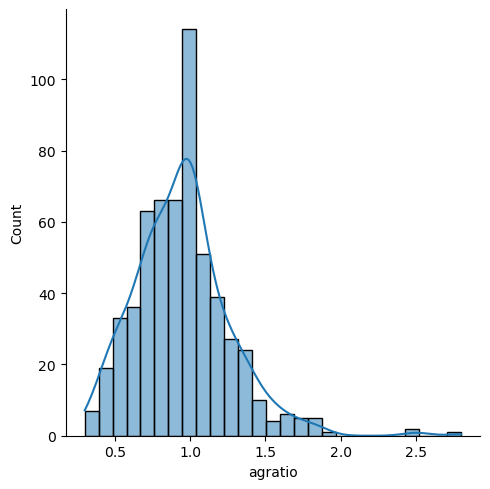

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.displot(data=data['agratio'],kde=True)
plt.show()

By observing above plot, we can say that data is skewed to right side. Now we will find the median of agratio column and use it to impute null values

In [ ]:
data['agratio'].fillna(data['agratio'].median(), inplace=True)

C:\Users\nikhi\AppData\Local\Temp\ipykernel_17660\1030639786.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['agratio'].fillna(data['agratio'].median(), inplace=True)


In [ ]:
data.loc[data['agratio'].isnull()]

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target


### Label issue in target column

As per documentation the existence of liver disease is labelled as 1, and if not its 2

In [ ]:
data['target']

0      1
1      1
2      1
3      1
4      1
      ..
578    2
579    1
580    1
581    1
582    2
Name: target, Length: 583, dtype: int64

In [ ]:
data['target'] = data['target'].map({1:1,2:0})

In [ ]:
data['target']

0      1
1      1
2      1
3      1
4      1
      ..
578    0
579    1
580    1
581    1
582    0
Name: target, Length: 583, dtype: int64

Now that we have used map function to map the values to 0 and 1

In [ ]:
data

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,0
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [ ]:
data.to_csv('cleaned_data.csv')

### Identifying outliers & Imputing outliers

In [ ]:
data.columns

Index(['age', 'gender', 'tbilirubin', 'dbilirubin', 'alp', 'alt', 'ast',
       'tpro', 'albumin', 'agratio', 'target'],
      dtype='object')

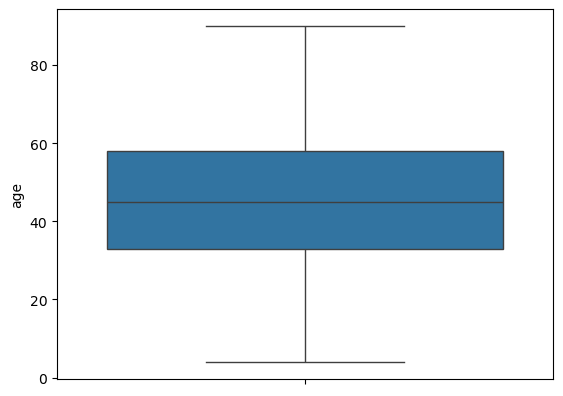

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=data['age'])
plt.show()

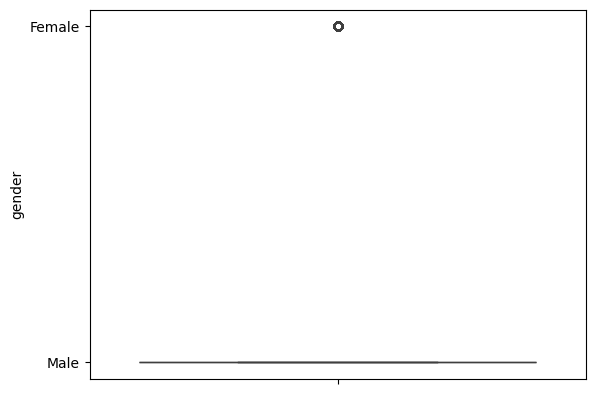

In [ ]:
sns.boxplot(data=data['gender'])
plt.show()

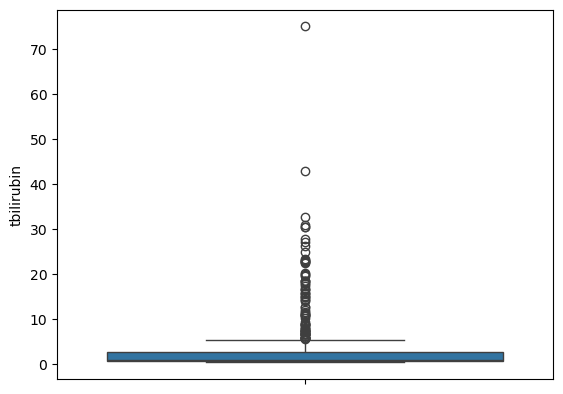

In [ ]:
sns.boxplot(data=data['tbilirubin'])
plt.show()

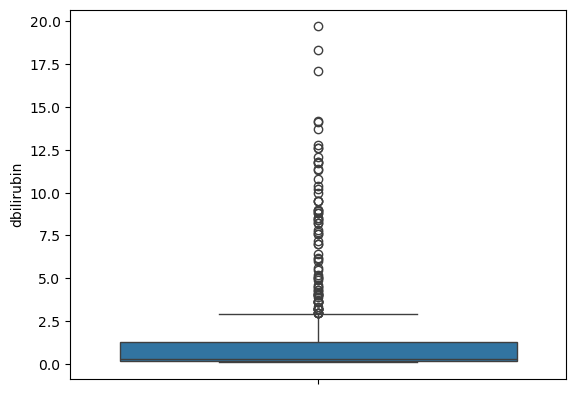

In [ ]:
sns.boxplot(data=data['dbilirubin'])
plt.show()

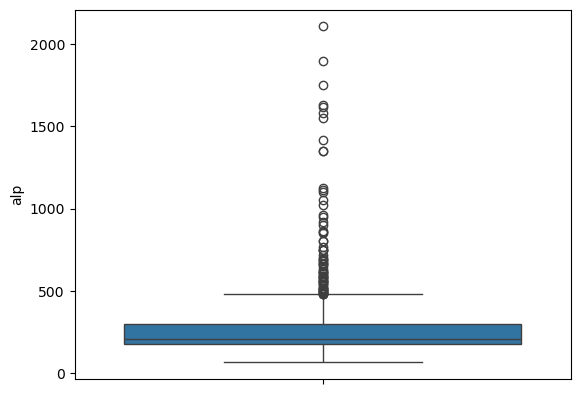

In [ ]:
sns.boxplot(data=data['alp'])
plt.show()

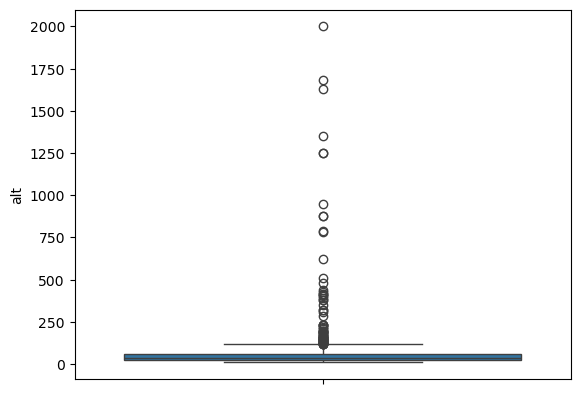

In [ ]:
sns.boxplot(data=data['alt'])
plt.show()

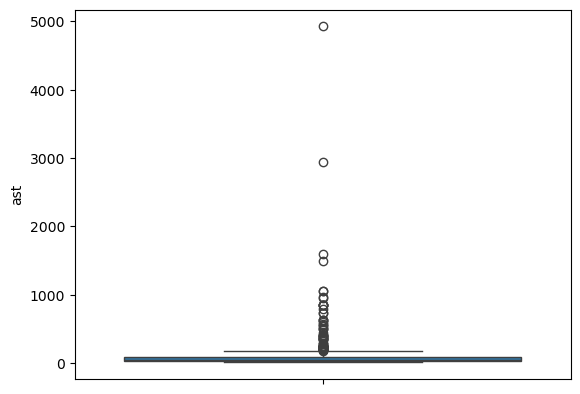

In [ ]:
sns.boxplot(data=data['ast'])
plt.show()

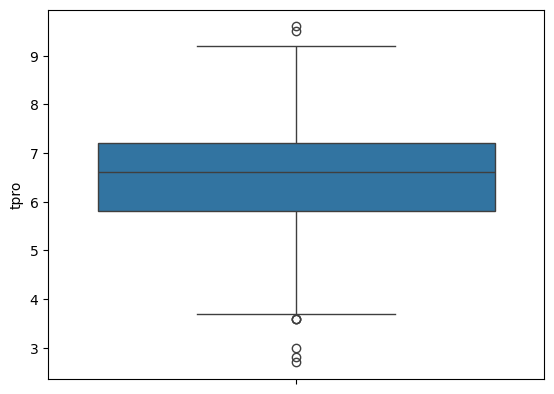

In [ ]:
sns.boxplot(data=data['tpro'])
plt.show()

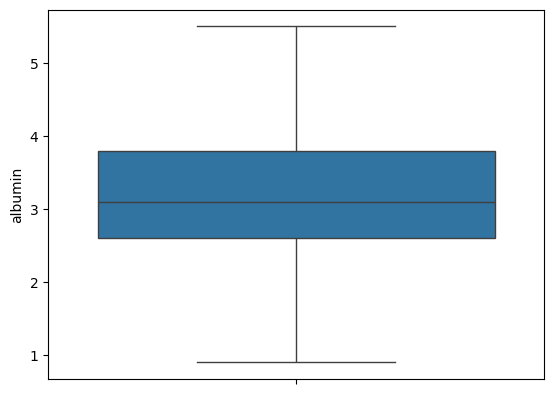

In [ ]:
sns.boxplot(data=data['albumin'])
plt.show()

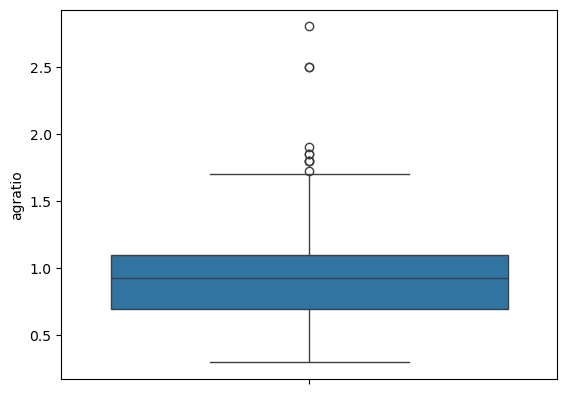

In [ ]:
sns.boxplot(data=data['agratio'])
plt.show()

### Outlier Detection & Imputation using IQR Method

**Approach:**
- **IQR (Interquartile Range) Method**: A statistical approach to identify outliers
- **Formula**:
  - Q1 = 25th percentile, Q3 = 75th percentile
  - IQR = Q3 - Q1
  - Lower Bound = Q1 - 1.5 × IQR
  - Upper Bound = Q3 + 1.5 × IQR
  - Any value outside [Lower Bound, Upper Bound] is an outlier

- **Imputation Strategy**: Cap outliers at the bounds (winsorization)
  - Values below lower bound → set to lower bound
  - Values above upper bound → set to upper bound
  - This preserves the distribution while removing extreme values

- **Note**: Gender column is excluded as it's categorical

In [ ]:
### Step 1: Define numeric columns (exclude gender)
numeric_columns = data.select_dtypes(include=['float64', 'int64']).columns.tolist()
# Remove gender column
if 'gender' in numeric_columns:
    numeric_columns.remove('gender')
numeric_columns = numeric_columns[:-1]
print("Columns to process for outlier imputation:")
print(numeric_columns)

Columns to process for outlier imputation:
['age', 'tbilirubin', 'dbilirubin', 'alp', 'alt', 'ast', 'tpro', 'albumin', 'agratio']


In [ ]:
### Step 2: Calculate IQR bounds for each column
outlier_bounds = {}

for col in numeric_columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound
    }

# Display the bounds in a structured format
import pandas as pd
bounds_df = pd.DataFrame(outlier_bounds).T
print("Outlier Bounds for Each Column (using IQR method):")
print(bounds_df.round(3))

Outlier Bounds for Each Column (using IQR method):
               Q1     Q3    IQR  Lower_Bound  Upper_Bound
age          33.0   58.0   25.0        -4.50        95.50
tbilirubin    0.8    2.6    1.8        -1.90         5.30
dbilirubin    0.2    1.3    1.1        -1.45         2.95
alp         175.5  298.0  122.5        -8.25       481.75
alt          23.0   60.5   37.5       -33.25       116.75
ast          25.0   87.0   62.0       -68.00       180.00
tpro          5.8    7.2    1.4         3.70         9.30
albumin       2.6    3.8    1.2         0.80         5.60
agratio       0.7    1.1    0.4         0.10         1.70


In [ ]:
### Step 3: Identify outliers in each column
outlier_summary = []

for col in numeric_columns:
    lower_bound = outlier_bounds[col]['Lower_Bound']
    upper_bound = outlier_bounds[col]['Upper_Bound']

    # Count outliers
    outliers_below = (data[col] < lower_bound).sum()
    outliers_above = (data[col] > upper_bound).sum()
    total_outliers = outliers_below + outliers_above

    outlier_summary.append({
        'Column': col,
        'Outliers_Below': outliers_below,
        'Outliers_Above': outliers_above,
        'Total_Outliers': total_outliers,
        'Percentage': round((total_outliers / len(data)) * 100, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
print("\nOutlier Summary:")
print(outlier_summary_df.to_string(index=False))


Outlier Summary:
    Column  Outliers_Below  Outliers_Above  Total_Outliers  Percentage
       age               0               0               0        0.00
tbilirubin               0              84              84       14.41
dbilirubin               0              81              81       13.89
       alp               0              69              69       11.84
       alt               0              73              73       12.52
       ast               0              66              66       11.32
      tpro               6               2               8        1.37
   albumin               0               0               0        0.00
   agratio               0              10              10        1.72


In [ ]:
### Step 4: Impute outliers using Capping (Winsorization)
# Create a copy to track changes
data_before_imputation = data.copy()

# Apply capping to each column
for col in numeric_columns:
    lower_bound = outlier_bounds[col]['Lower_Bound']
    upper_bound = outlier_bounds[col]['Upper_Bound']

    # Cap values: keep values within bounds, replace outliers with bounds
    data[col] = data[col].clip(lower=lower_bound, upper=upper_bound)

print("Outlier imputation completed!")
print("\nComparison - Before and After Imputation:")
for col in numeric_columns:
    print(f"\n{col}:")
    print(f"  Before: min={data_before_imputation[col].min():.3f}, max={data_before_imputation[col].max():.3f}")
    print(f"  After:  min={data[col].min():.3f}, max={data[col].max():.3f}")

Outlier imputation completed!

Comparison - Before and After Imputation:

age:
  Before: min=4.000, max=90.000
  After:  min=4.000, max=90.000

tbilirubin:
  Before: min=0.400, max=75.000
  After:  min=0.400, max=5.300

dbilirubin:
  Before: min=0.100, max=19.700
  After:  min=0.100, max=2.950

alp:
  Before: min=63.000, max=2110.000
  After:  min=63.000, max=481.750

alt:
  Before: min=10.000, max=2000.000
  After:  min=10.000, max=116.750

ast:
  Before: min=10.000, max=4929.000
  After:  min=10.000, max=180.000

tpro:
  Before: min=2.700, max=9.600
  After:  min=3.700, max=9.300

albumin:
  Before: min=0.900, max=5.500
  After:  min=0.900, max=5.500

agratio:
  Before: min=0.300, max=2.800
  After:  min=0.300, max=1.700


In [ ]:
### Step 5: Verification - View data after outlier imputation
print("Data Summary after Outlier Imputation:")
print(data.describe())

Data Summary after Outlier Imputation:
              age  tbilirubin  dbilirubin         alp         alt         ast  \
count  583.000000  583.000000  583.000000  583.000000  583.000000  583.000000   
mean    44.746141    1.921441    0.879674  251.258576   47.893225   64.833619   
std     16.189833    1.654226    0.994324  109.474093   33.277688   53.660426   
min      4.000000    0.400000    0.100000   63.000000   10.000000   10.000000   
25%     33.000000    0.800000    0.200000  175.500000   23.000000   25.000000   
50%     45.000000    1.000000    0.300000  208.000000   35.000000   42.000000   
75%     58.000000    2.600000    1.300000  298.000000   60.500000   87.000000   
max     90.000000    5.300000    2.950000  481.750000  116.750000  180.000000   

             tpro     albumin     agratio      target  
count  583.000000  583.000000  579.000000  583.000000  
mean     6.487307    3.141852    0.940984    1.286449  
std      1.068356    0.795519    0.297361    0.452490  
min    

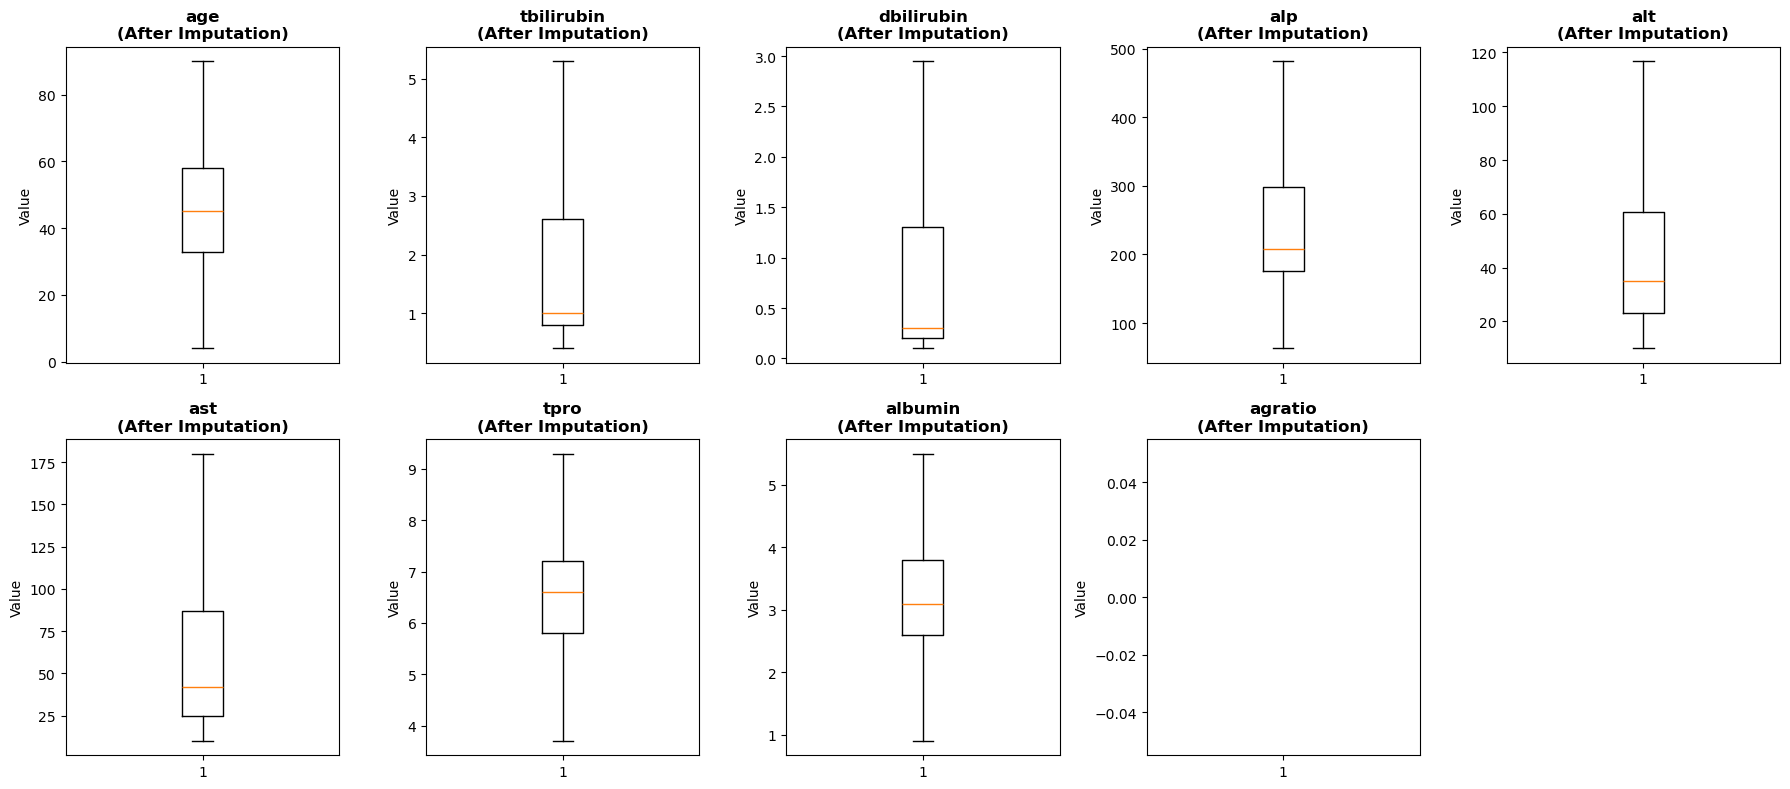

✓ Outliers have been successfully imputed!


In [ ]:
### Step 6: Boxplots after outlier imputation (showing the difference)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for idx, col in enumerate(numeric_columns):
    axes[idx].boxplot(data[col])
    axes[idx].set_title(f'{col}\n(After Imputation)', fontweight='bold')
    axes[idx].set_ylabel('Value')

# Hide the extra subplots if there are fewer than 10 columns
for idx in range(len(numeric_columns), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

print("✓ Outliers have been successfully imputed!")

In [ ]:
### Step 7: Save cleaned data and document the imputation
data.to_csv('cleaned_data_with_outliers_imputed.csv', index=False)
print("✓ Cleaned data saved to 'cleaned_data_with_outliers_imputed.csv'\n")

# Create a summary report for documentation
summary_report = f"""
================== OUTLIER IMPUTATION REPORT ==================

Method: IQR (InterQuartile Range) with Capping/Winsorization

Total Outliers Handled:
"""

for _, row in outlier_summary_df.iterrows():
    summary_report += f"\n  {row['Column']}: {row['Total_Outliers']} outliers ({row['Percentage']}%)"
    summary_report += f"\n    - Below lower bound: {row['Outliers_Below']}"
    summary_report += f"\n    - Above upper bound: {row['Outliers_Above']}"

summary_report += f"\n\nExcluded Column: gender (categorical variable)\n"
summary_report += "============================================================\n"

print(summary_report)

✓ Cleaned data saved to 'cleaned_data_with_outliers_imputed.csv'


================== OUTLIER IMPUTATION REPORT ==================

Method: IQR (InterQuartile Range) with Capping/Winsorization

Total Outliers Handled:

  age: 0 outliers (0.0%)
    - Below lower bound: 0
    - Above upper bound: 0
  tbilirubin: 84 outliers (14.41%)
    - Below lower bound: 0
    - Above upper bound: 84
  dbilirubin: 81 outliers (13.89%)
    - Below lower bound: 0
    - Above upper bound: 81
  alp: 69 outliers (11.84%)
    - Below lower bound: 0
    - Above upper bound: 69
  alt: 73 outliers (12.52%)
    - Below lower bound: 0
    - Above upper bound: 73
  ast: 66 outliers (11.32%)
    - Below lower bound: 0
    - Above upper bound: 66
  tpro: 8 outliers (1.37%)
    - Below lower bound: 6
    - Above upper bound: 2
  albumin: 0 outliers (0.0%)
    - Below lower bound: 0
    - Above upper bound: 0
  agratio: 10 outliers (1.72%)
    - Below lower bound: 0
    - Above upper bound: 10

Excluded Column: gende

### Feature Engineering

**Now we need to do Feature Engineering to Each and every column**
Steps involved are :
- Feature Scaling for numerical columns
- Feature encoding for categorical columns

In [ ]:
import pandas as pd

datas = pd.read_csv('cleaned_data_with_outliers_imputed.csv')
datas

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
0,65,Female,0.7,0.10,187.00,16.0,18,6.8,3.3,0.90,1
1,62,Male,5.3,2.95,481.75,64.0,100,7.5,3.2,0.74,1
2,62,Male,5.3,2.95,481.75,60.0,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.40,182.00,14.0,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.00,195.00,27.0,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.10,481.75,20.0,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.10,98.00,35.0,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.20,245.00,48.0,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.50,184.00,29.0,32,6.8,3.4,1.00,1


In [ ]:
datas['target'] = datas['target'].map({1:1,2:0})

In [ ]:
datas.to_csv('cleaned_data_with_outliers_imputed_encoded.csv')

In [ ]:
import pandas as pd

datas = pd.read_csv('cleaned_data_with_outliers_imputed_encoded.csv')
datas

,Unnamed: 0,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
0,0,65,0,0.7,0.10,187.00,16.0,18,6.8,3.3,0.90,1
1,1,62,1,5.3,2.95,481.75,64.0,100,7.5,3.2,0.74,1
2,2,62,1,5.3,2.95,481.75,60.0,68,7.0,3.3,0.89,1
3,3,58,1,1.0,0.40,182.00,14.0,20,6.8,3.4,1.00,1
4,4,72,1,3.9,2.00,195.00,27.0,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...,...
578,578,60,1,0.5,0.10,481.75,20.0,34,5.9,1.6,0.37,0
579,579,40,1,0.6,0.10,98.00,35.0,31,6.0,3.2,1.10,1
580,580,52,1,0.8,0.20,245.00,48.0,49,6.4,3.2,1.00,1
581,581,31,1,1.3,0.50,184.00,29.0,32,6.8,3.4,1.00,1


In [ ]:
datas = datas.drop('Unnamed: 0',axis=1)
datas

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
0,65,0,0.7,0.10,187.00,16.0,18,6.8,3.3,0.90,1
1,62,1,5.3,2.95,481.75,64.0,100,7.5,3.2,0.74,1
2,62,1,5.3,2.95,481.75,60.0,68,7.0,3.3,0.89,1
3,58,1,1.0,0.40,182.00,14.0,20,6.8,3.4,1.00,1
4,72,1,3.9,2.00,195.00,27.0,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,1,0.5,0.10,481.75,20.0,34,5.9,1.6,0.37,0
579,40,1,0.6,0.10,98.00,35.0,31,6.0,3.2,1.10,1
580,52,1,0.8,0.20,245.00,48.0,49,6.4,3.2,1.00,1
581,31,1,1.3,0.50,184.00,29.0,32,6.8,3.4,1.00,1


In [ ]:
x = datas.drop('target',axis=1)
y = datas.target

In [ ]:
x

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio
0,65,0,0.7,0.10,187.00,16.0,18,6.8,3.3,0.90
1,62,1,5.3,2.95,481.75,64.0,100,7.5,3.2,0.74
2,62,1,5.3,2.95,481.75,60.0,68,7.0,3.3,0.89
3,58,1,1.0,0.40,182.00,14.0,20,6.8,3.4,1.00
4,72,1,3.9,2.00,195.00,27.0,59,7.3,2.4,0.40
...,...,...,...,...,...,...,...,...,...,...
578,60,1,0.5,0.10,481.75,20.0,34,5.9,1.6,0.37
579,40,1,0.6,0.10,98.00,35.0,31,6.0,3.2,1.10
580,52,1,0.8,0.20,245.00,48.0,49,6.4,3.2,1.00
581,31,1,1.3,0.50,184.00,29.0,32,6.8,3.4,1.00


In [ ]:
nums = x.select_dtypes('number')
nums

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio
0,65,0,0.7,0.10,187.00,16.0,18,6.8,3.3,0.90
1,62,1,5.3,2.95,481.75,64.0,100,7.5,3.2,0.74
2,62,1,5.3,2.95,481.75,60.0,68,7.0,3.3,0.89
3,58,1,1.0,0.40,182.00,14.0,20,6.8,3.4,1.00
4,72,1,3.9,2.00,195.00,27.0,59,7.3,2.4,0.40
...,...,...,...,...,...,...,...,...,...,...
578,60,1,0.5,0.10,481.75,20.0,34,5.9,1.6,0.37
579,40,1,0.6,0.10,98.00,35.0,31,6.0,3.2,1.10
580,52,1,0.8,0.20,245.00,48.0,49,6.4,3.2,1.00
581,31,1,1.3,0.50,184.00,29.0,32,6.8,3.4,1.00


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
x_scaled

array([[ 1.25209764, -1.76228085, -0.73901007, ...,  0.2929374 ,
         0.19896867, -0.13794629],
       [ 1.06663704,  0.56744644,  2.04413443, ...,  0.94871223,
         0.07315659, -0.67647744],
       [ 1.06663704,  0.56744644,  2.04413443, ...,  0.48030163,
         0.19896867, -0.17160449],
       ...,
       [ 0.44843504,  0.56744644, -0.67850693, ..., -0.08179108,
         0.07315659,  0.19863568],
       [-0.84978917,  0.56744644, -0.37599122, ...,  0.2929374 ,
         0.32478075,  0.19863568],
       [-0.41704777,  0.56744644, -0.55750064, ...,  0.76134799,
         1.58290153,  1.88154554]])

In [ ]:
x_scaled = pd.DataFrame(x_scaled)
x_scaled

,0,1,2,3,4,5,6,7,8,9
0,1.252098,-1.762281,-0.739010,-0.784798,-0.587479,-0.959220,-0.873527,0.292937,0.198969,-0.137946
1,1.066637,0.567446,2.044134,2.083933,2.107251,0.484427,0.655913,0.948712,0.073157,-0.676477
2,1.066637,0.567446,2.044134,2.083933,2.107251,0.364123,0.059058,0.480302,0.198969,-0.171604
3,0.819356,0.567446,-0.557501,-0.482827,-0.633191,-1.019372,-0.836224,0.292937,0.324781,0.198636
4,1.684839,0.567446,1.197090,1.127689,-0.514340,-0.628384,-0.108807,0.761348,-0.933340,-1.820856
...,...,...,...,...,...,...,...,...,...,...
578,0.942997,0.567446,-0.860016,-0.784798,2.107251,-0.838916,-0.575100,-0.550202,-1.939837,-1.921831
579,-0.293407,0.567446,-0.799513,-0.784798,-1.401155,-0.387776,-0.631055,-0.456520,0.073157,0.535218
580,0.448435,0.567446,-0.678507,-0.684141,-0.057219,0.003211,-0.295324,-0.081791,0.073157,0.198636
581,-0.849789,0.567446,-0.375991,-0.382169,-0.614907,-0.568232,-0.612403,0.292937,0.324781,0.198636


In [ ]:
x_scaled.columns = x.columns

In [ ]:
x_scaled

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio
0,1.252098,-1.762281,-0.739010,-0.784798,-0.587479,-0.959220,-0.873527,0.292937,0.198969,-0.137946
1,1.066637,0.567446,2.044134,2.083933,2.107251,0.484427,0.655913,0.948712,0.073157,-0.676477
2,1.066637,0.567446,2.044134,2.083933,2.107251,0.364123,0.059058,0.480302,0.198969,-0.171604
3,0.819356,0.567446,-0.557501,-0.482827,-0.633191,-1.019372,-0.836224,0.292937,0.324781,0.198636
4,1.684839,0.567446,1.197090,1.127689,-0.514340,-0.628384,-0.108807,0.761348,-0.933340,-1.820856
...,...,...,...,...,...,...,...,...,...,...
578,0.942997,0.567446,-0.860016,-0.784798,2.107251,-0.838916,-0.575100,-0.550202,-1.939837,-1.921831
579,-0.293407,0.567446,-0.799513,-0.784798,-1.401155,-0.387776,-0.631055,-0.456520,0.073157,0.535218
580,0.448435,0.567446,-0.678507,-0.684141,-0.057219,0.003211,-0.295324,-0.081791,0.073157,0.198636
581,-0.849789,0.567446,-0.375991,-0.382169,-0.614907,-0.568232,-0.612403,0.292937,0.324781,0.198636


In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x_scaled,y,test_size=0.3,random_state=45)

In [ ]:
trains = pd.concat([x_train,y_train],axis=1)

In [ ]:
trains

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
84,-0.787969,0.567446,-0.799513,-0.784798,-0.130358,-0.087017,-0.631055,0.948712,1.457089,1.343014,1
136,0.077514,-1.762281,1.681116,1.329003,0.537039,0.424275,0.469396,-0.081791,-0.807528,-1.147692,1
365,-0.293407,0.567446,-0.739010,-0.684141,-0.688046,-0.598308,-0.407234,-1.112294,-0.933340,-0.474528,0
190,0.942997,0.567446,2.044134,2.083933,0.573609,2.070934,0.917037,0.105573,0.702217,1.107407,1
522,0.077514,-1.762281,-0.678507,-0.684141,-0.605764,-0.718612,-0.929482,1.323441,0.702217,-0.474528,1
...,...,...,...,...,...,...,...,...,...,...,...
15,-1.220710,0.567446,-0.799513,-0.784798,-0.624049,1.296478,-0.220717,-0.924930,-1.059152,-0.811110,0
377,-1.529811,-1.762281,-0.799513,-0.684141,-0.450343,-1.079524,-0.966786,-0.362837,-0.178468,-0.137946,0
163,-0.355228,0.567446,-0.012972,0.020459,-0.651476,-0.177244,-0.052852,0.855030,1.457089,1.477647,1
544,0.572075,-1.762281,2.044134,2.083933,0.902736,0.574655,-0.425886,0.480302,0.073157,-0.474528,1


In [ ]:
tests = pd.concat([x_test,y_test],axis=1)

In [ ]:
tests

,age,gender,tbilirubin,dbilirubin,alp,alt,ast,tpro,albumin,agratio,target
171,-0.046127,-1.762281,-0.012972,-0.281512,0.427330,2.070934,2.148050,0.105573,0.198969,0.198636,1
483,-0.911609,0.567446,-0.678507,-0.684141,-0.633191,-0.056941,-0.146110,1.229759,1.457089,0.871800,0
133,0.510255,0.567446,-0.618004,-0.482827,-0.121216,-0.929144,-0.948134,0.105573,-0.304280,-0.474528,1
210,-1.035250,0.567446,-0.678507,-0.583484,-0.560052,-0.838916,-0.948134,-2.236480,-0.933340,1.544964,1
214,-0.417048,0.567446,-0.133979,0.121117,-0.651476,-0.899068,-0.575100,0.667666,0.576405,0.198636,1
...,...,...,...,...,...,...,...,...,...,...,...
560,1.313918,0.567446,2.044134,2.083933,0.957591,2.070934,2.148050,0.011891,-1.184964,-1.820856,1
156,-0.787969,0.567446,-0.618004,-0.583484,1.926688,0.664883,0.320182,-0.269155,-0.052655,0.198636,1
257,-0.046127,0.567446,-0.678507,-0.684141,0.765600,2.070934,0.394789,-0.831248,-0.178468,0.535218,1
138,-1.653452,0.567446,-0.678507,-0.684141,0.281051,0.725035,1.401982,-0.924930,-0.807528,-0.474528,1


In [ ]:
trains.to_csv('trains.csv')
tests.to_csv('tests.csv')